# Experimento CNN - CIFAR-10

**Estudiante:** Zahir Jadil Rivera Cruz  
**Código de matrícula:** 022101099h  
**Semilla individual:** 99

Este notebook sirve como banco de pruebas, análisis exploratorio (EDA) y visualización de muestras del dataset CIFAR-10, además de validar la arquitectura CNN definida en `src/model.py` antes del entrenamiento completo (ejecutado con `src/train.py`).

## 1. Imports y configuración del path

Se agrega la carpeta `src/` al `sys.path` para poder reutilizar las funciones ya definidas en `dataset.py`, `model.py` y `train.py`, evitando duplicar código.

In [1]:
import sys, os
sys.path.append(os.path.abspath(os.path.join("..", "src")))

import numpy as np
import torch
import matplotlib.pyplot as plt

from dataset import get_dataloaders, show_sample_grid, CLASSES, SEED, set_seed, OUTPUTS_DIR
from model import CNNCifar10, validate_forward_pass
from train import build_training_components, run_one_epoch, train_model, plot_loss_accuracy

print("Semilla individual utilizada:", SEED)
set_seed(SEED)

Semilla individual utilizada: 99


## 2. Carga del dataset CIFAR-10 y partición con semilla (Pregunta 1)

`get_dataloaders()` descarga el dataset (si no existe localmente), aplica el pipeline de transformaciones (ToTensor + Normalize + Data Augmentation en train) y realiza la partición entrenamiento/validación usando `torch.Generator().manual_seed(99)`.

In [2]:
train_loader, val_loader, test_loader = get_dataloaders()

print("Batches de entrenamiento:", len(train_loader))
print("Batches de validación:", len(val_loader))
print("Batches de prueba:", len(test_loader))

images, labels = next(iter(train_loader))
print("Shape de un batch de imágenes (B, C, H, W):", images.shape)
print("Shape de las etiquetas:", labels.shape)

[dataset.py] Tamano total de entrenamiento original: 50000
[dataset.py] Particion -> train: 40000 | val: 10000 | test: 10000
Batches de entrenamiento: 625
Batches de validación: 157
Batches de prueba: 157
Shape de un batch de imágenes (B, C, H, W): torch.Size([64, 3, 32, 32])
Shape de las etiquetas: torch.Size([64])


## 3. EDA: distribución de clases

Se cuentan las etiquetas del conjunto de entrenamiento (antes del split) para verificar que CIFAR-10 está balanceado entre sus 10 clases.

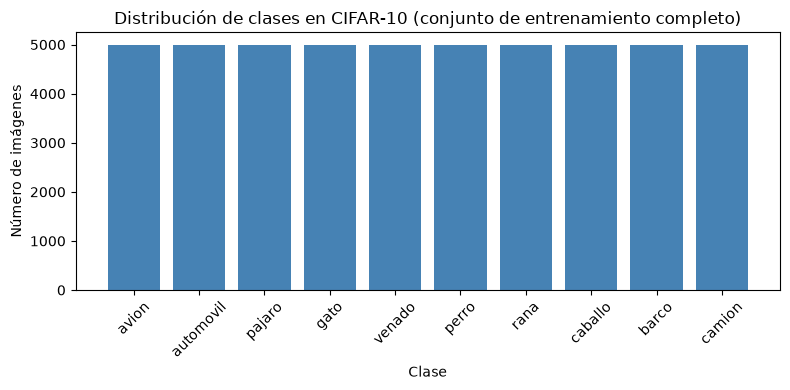

     avion: 5000 imágenes
 automovil: 5000 imágenes
    pajaro: 5000 imágenes
      gato: 5000 imágenes
    venado: 5000 imágenes
     perro: 5000 imágenes
      rana: 5000 imágenes
   caballo: 5000 imágenes
     barco: 5000 imágenes
    camion: 5000 imágenes


In [3]:
from torchvision import datasets

raw_train = datasets.CIFAR10(root=os.path.join("..", "data"), train=True, download=True)
labels_array = np.array(raw_train.targets)
unique, counts = np.unique(labels_array, return_counts=True)

plt.figure(figsize=(8, 4))
plt.bar([CLASSES[i] for i in unique], counts, color="steelblue")
plt.title("Distribución de clases en CIFAR-10 (conjunto de entrenamiento completo)")
plt.xlabel("Clase")
plt.ylabel("Número de imágenes")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

for cls_idx, cnt in zip(unique, counts):
    print(f"{CLASSES[cls_idx]:>10s}: {cnt} imágenes")

## 4. Visualización de muestras del dataset (Pregunta 1, punto 2)

Cuadrícula con 12 imágenes de ejemplo y su clase real, guardada también en `outputs/sample_grid.png`.

[dataset.py] Cuadricula de muestras guardada en: ..\outputs\sample_grid.png


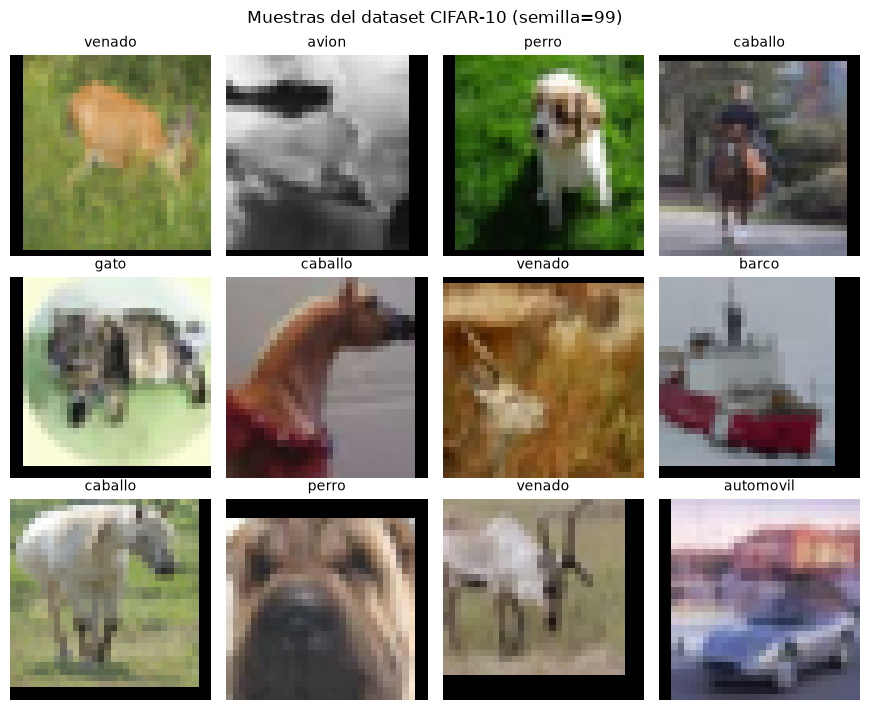

In [4]:
show_sample_grid(train_loader, n_images=12, save_path=os.path.join("..", "outputs", "sample_grid.png"))

## 5. Validación de la arquitectura CNN y flujo de tensores 4D (Pregunta 3)

Se instancia el modelo y se pasa un batch simulado de forma `(Batch_Size, Channels, Height, Width)` para comprobar, con una aserción, que las dimensiones fluyen correctamente hasta la capa de salida (10 clases).

In [5]:
model = validate_forward_pass(batch_size=8)


[model.py] Validando forward pass con batch simulado (N=8)...
  entrada           : (8, 3, 32, 32)
  despues block1    : (8, 32, 16, 16)
  despues block2    : (8, 64, 8, 8)
  despues block3    : (8, 128, 4, 4)
  despues flatten   : (8, 2048)
  salida (logits)   : (8, 10)
[model.py] OK: el tensor 4D fluyo correctamente por toda la arquitectura.



## 6. Demostración rápida del ciclo de entrenamiento (Pregunta 4)

Para no duplicar el cómputo pesado, aquí se ejecutan solo **3 épocas de demostración** sobre un modelo nuevo, para comprobar que el bucle de entrenamiento (`CrossEntropyLoss` + `Adam`) funciona correctamente. El entrenamiento **completo** (15 épocas) se ejecuta con el script `src/train.py`, el cual genera los artefactos oficiales `outputs/loss_accuracy.png` y `outputs/confusion_matrix.png` que se documentan en el `README.md`.

In [6]:
demo_model = CNNCifar10(num_classes=10)
demo_history = train_model(demo_model, train_loader, val_loader, epochs=3)
plot_loss_accuracy(demo_history, os.path.join("..", "outputs", "demo_loss_accuracy.png"))

Epoca 01/3 | train_loss=1.6848 train_acc=0.3776 | val_loss=1.3373 val_acc=0.5213 | tiempo=27.3s


Epoca 02/3 | train_loss=1.3342 train_acc=0.5158 | val_loss=1.0953 val_acc=0.6110 | tiempo=26.6s


Epoca 03/3 | train_loss=1.1565 train_acc=0.5861 | val_loss=0.9618 val_acc=0.6589 | tiempo=26.2s


[train.py] Curvas de aprendizaje guardadas en: ..\outputs\demo_loss_accuracy.png


## 7. Conclusión

Este notebook confirma que: (1) el dataset CIFAR-10 se carga y particiona correctamente con la semilla individual 99; (2) la arquitectura CNN procesa sin errores los tensores 4D; y (3) el bucle de entrenamiento optimiza correctamente el `Loss` y mejora el `Accuracy` a través de las épocas. Los resultados finales, con las 15 épocas completas y el análisis crítico de overfitting/underfitting, se documentan en el `README.md` del repositorio.